dt (seconds), first few shots:
0    0.054066
1    0.057027
2    0.052008
3    0.062010
4    0.062026
dtype: float64
     x1
0  43.0
1  43.0
2  43.0
3  43.0
4  43.0
length of node1_t: 100 | length of node2_t: 100 | length of distances: 100
Line counts match -- proceeding.

dx (meters), first few shots:
0    41.8
1    41.8
2    41.8
3    41.8
4    41.8
dtype: float64

Per-shot velocity (dx/dt), first few shots:
0      773.126550
1      732.984818
2      803.727527
3      674.081694
4      673.915852
         ...     
95     365.914792
96    1696.264641
97     412.700306
98     402.938694
99     805.894220
Length: 100, dtype: float64


<Figure size 1200x800 with 0 Axes>

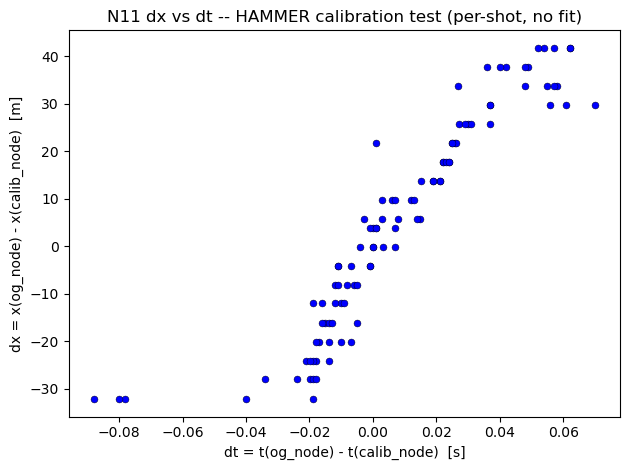

In [1]:
# 2. compute dt

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# computing dt
# og_node_t = pd.read_csv(r"D:\arrival_markers\2511\2511_hammer_markers_clean.txt", skiprows=1, header=None, names=["t1"])
# calib_node_t = pd.read_csv(r"D:\arrival_markers\C2511\C2511_hammer_markers_clean_later_arrivals.txt", skiprows=1, header=None, names=["t2"])

og_node_t = pd.read_csv(r"D:\arrival_markers\2511\2511_hammer_markers_clean.txt", skiprows=1, header=None, names=["t1"])
calib_node_t = pd.read_csv(r"D:\arrival_markers\C2511\C2511_hammer_markers_clean_later_arrivals.txt", skiprows=1, header=None, names=["t2"])


og_node_t["t1"] = pd.to_datetime(og_node_t["t1"])
calib_node_t["t2"] = pd.to_datetime(calib_node_t["t2"])

dt = (og_node_t["t1"] - calib_node_t["t2"]).dt.total_seconds()

print("dt (seconds), first few shots:")
print(dt.head())

# 3. compute dx
transect_x = 44.2 # transect length (meters) # check what N11's was

og_node_x = pd.read_csv(r"D:\arrival_markers\arrival_dx\N11_hammer_dx.txt",
                 header=None, names=["x1"]) # impact locations from field notes

print(og_node_x.head())

calib_node_x = pd.DataFrame({"x2": transect_x - og_node_x["x1"]})

# vector length check
n_t1, n_t2, n_x = len(og_node_t), len(calib_node_t), len(og_node_x)
print(f"length of node1_t: {n_t1} | length of node2_t: {n_t2} | length of distances: {n_x}")

# turn this into an if statement in full pipeline
assert n_t1 == n_t2 == n_x, (
    f"Line count mismatch (node1={n_t1}, node2={n_t2}, distances={n_x}). "
    f"These three files must correspond line-for-line -- find and fix "
    f"the mismatch before proceeding, since every row after the "
    f"divergence point would otherwise be silently misaligned."
)
print("Line counts match -- proceeding.\n")


# compute dx

dx = og_node_x["x1"] - calib_node_x["x2"]

dx.to_csv(r"D:\arrival_markers\arrival_dx\C2511_hammer_x.txt",
         index=False, header=None)

print("dx (meters), first few shots:")
print(dx.head())

# 4. compute p-wave velocity
# computed per-shot, no averaging
from matplotlib.ticker import AutoMinorLocator, MultipleLocator

v_per_shot = dx / dt
print("\nPer-shot velocity (dx/dt), first few shots:")
print(v_per_shot)#.head())

plt.figure(figsize=(12, 8))
fig, ax = plt.subplots()
# ax.xaxis.set_major_locator(MultipleLocator(0.005))
# ax.xaxis.set_major_formatter('{x:.0f}')
ax.scatter(dt, dx, color="blue", s=25, edgecolors="k", linewidths=0.3)
#plt.ylim(-39, 45)
#plt.xlim(-0.075, 0.075)
plt.xlabel("dt = t(og_node) - t(calib_node)  [s]")
plt.ylabel("dx = x(og_node) - x(calib_node)  [m]")
plt.title("N11 dx vs dt -- HAMMER calibration test (per-shot, no fit)")
plt.tight_layout()
#plt.savefig(r"D:\arrival_markers\arrival_plots\N11_hammer_dx_vs_dt_pershot.png", dpi=150)
plt.show()

dt (seconds), first few shots:
0    0.054066
1    0.057027
2    0.052008
3    0.062010
4    0.062026
dtype: float64
     x1
0  43.0
1  43.0
2  43.0
3  43.0
4  43.0
length of node1_t: 100 | length of node2_t: 100 | length of distances: 100
Line counts match -- proceeding.

dx (meters), first few shots:
0    41.8
1    41.8
2    41.8
3    41.8
4    41.8
dtype: float64

Per-shot velocity (dx/dt), first few shots:
0      773.126550
1      732.984818
2      803.727527
3      674.081694
4      673.915852
         ...     
95     365.914792
96    1696.264641
97     412.700306
98     402.938694
99     805.894220
Length: 100, dtype: float64


<Figure size 2000x1600 with 0 Axes>

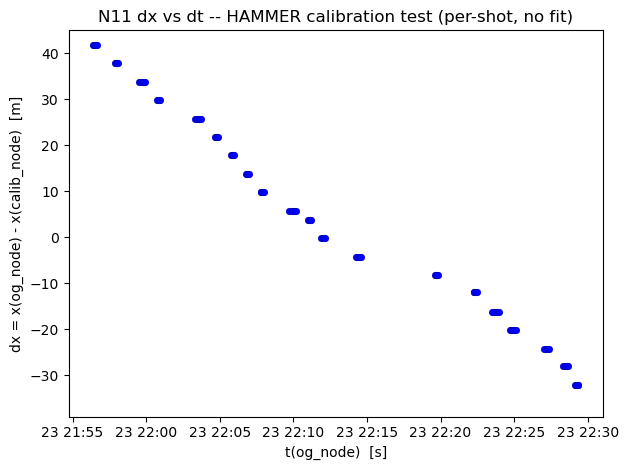

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# computing dt
# og_node_t = pd.read_csv(r"D:\arrival_markers\2511\2511_hammer_markers_clean.txt", skiprows=1, header=None, names=["t1"])
# calib_node_t = pd.read_csv(r"D:\arrival_markers\C2511\C2511_hammer_markers_clean_later_arrivals.txt", skiprows=1, header=None, names=["t2"])


og_node_t = pd.read_csv(r"D:\arrival_markers\2511\2511_hammer_markers_clean.txt", skiprows=1, header=None, names=["t1"])
calib_node_t = pd.read_csv(r"D:\arrival_markers\C2511\C2511_hammer_markers_clean_later_arrivals.txt", skiprows=1, header=None, names=["t2"])

og_node_t["t1"] = pd.to_datetime(og_node_t["t1"])
calib_node_t["t2"] = pd.to_datetime(calib_node_t["t2"])

dt = (og_node_t["t1"] - calib_node_t["t2"]).dt.total_seconds()

print("dt (seconds), first few shots:")
print(dt.head())

# 3. compute dx
transect_x = 44.2 # transect length (meters) # check what N11's was

og_node_x = pd.read_csv(r"D:\arrival_markers\arrival_dx\N11_hammer_dx.txt",
                 header=None, names=["x1"]) # impact locations from field notes

print(og_node_x.head())

calib_node_x = pd.DataFrame({"x2": transect_x - og_node_x["x1"]})

# vector length check
n_t1, n_t2, n_x = len(og_node_t), len(calib_node_t), len(og_node_x)
print(f"length of node1_t: {n_t1} | length of node2_t: {n_t2} | length of distances: {n_x}")

# turn this into an if statement in full pipeline
assert n_t1 == n_t2 == n_x, (
    f"Line count mismatch (node1={n_t1}, node2={n_t2}, distances={n_x}). "
    f"These three files must correspond line-for-line -- find and fix "
    f"the mismatch before proceeding, since every row after the "
    f"divergence point would otherwise be silently misaligned."
)
print("Line counts match -- proceeding.\n")


# compute dx

dx = og_node_x["x1"] - calib_node_x["x2"]

dx.to_csv(r"D:\arrival_markers\arrival_dx\C2511_hammer_x.txt",
         index=False, header=None)

print("dx (meters), first few shots:")
print(dx.head())

# 4. compute p-wave velocity
# computed per-shot, no averaging
from matplotlib.ticker import AutoMinorLocator, MultipleLocator

v_per_shot = dx / dt
print("\nPer-shot velocity (dx/dt), first few shots:")
print(v_per_shot)#.head())

plt.figure(figsize=(20, 16))
fig, ax = plt.subplots()
# ax.xaxis.set_major_locator(MultipleLocator(0.005))
# ax.xaxis.set_major_formatter('{x:.0f}')
ax.scatter(og_node_t["t1"], dx, color="blue", s=25, edgecolors="k", linewidths=0.1)
plt.ylim(-39, 45)
#plt.xlim(0, 10000)
plt.xlabel("t(og_node)  [s]")
plt.ylabel("dx = x(og_node) - x(calib_node)  [m]")
plt.title("N11 dx vs dt -- HAMMER calibration test (per-shot, no fit)")
plt.tight_layout()
#plt.savefig(r"D:\arrival_markers\arrival_plots\N11_hammer_dx_vs_dt_pershot.png", dpi=150)
plt.show()

n=== OUTLIER CHECK ===
QC fit (for residuals only): slope=683.357 m/s, intercept=-0.568318 m
Median residual: 0.7194 m | MAD: 6.3392 m
Flagging threshold: 1.75 MADs

19 shot(s) flagged for review in Snuffler (sorted worst first):

 shot_index                    t1_og_node                 t2_calib_node  dist_og_node  dist_calib_node    dt_sec  dx_m  residual_m  mod_z_score
         95 2025-10-23 22:29:07.893047094 2025-10-23 22:29:07.981045723           6.0             38.2 -0.087999 -32.2   28.502802     4.382815
         98 2025-10-23 22:29:18.029096842 2025-10-23 22:29:18.109009743           6.0             38.2 -0.079913 -32.2   22.977362     3.511181
         27 2025-10-23 22:04:46.570054293 2025-10-23 22:04:46.569062948          33.0             11.2  0.000991  21.8   21.690875     3.308239
         97 2025-10-23 22:29:15.209022760 2025-10-23 22:29:15.287045479           6.0             38.2 -0.078023 -32.2   21.685693     3.307421
         96 2025-10-23 22:29:11.938026905 2025-10

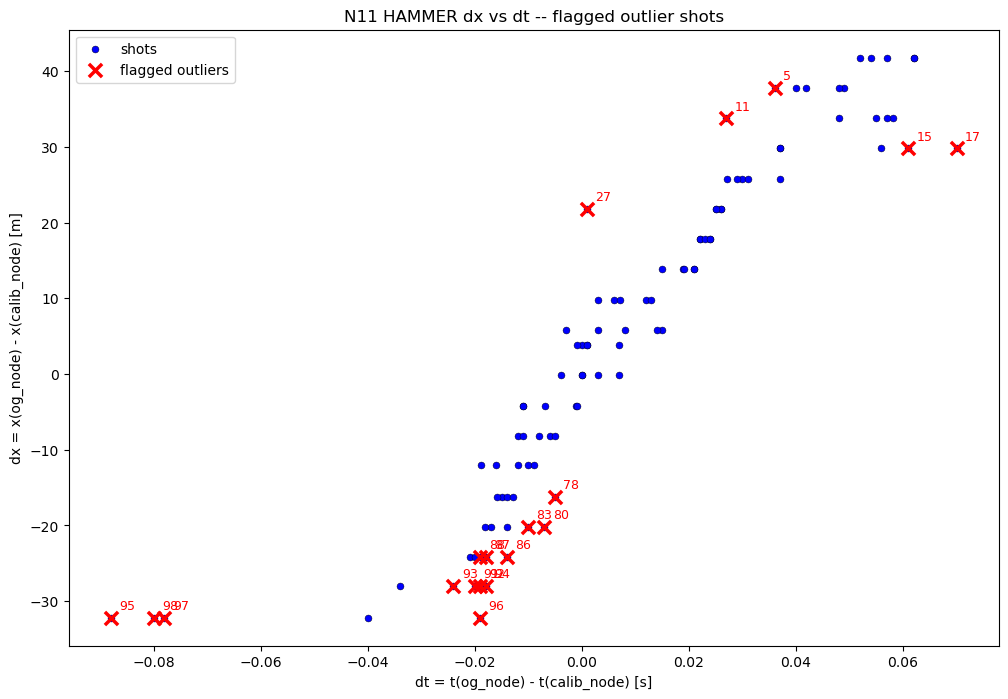

In [3]:
# residual tracking
# uses median + median absolute deviation (since outliers would inflate mean + SD)
# builds table of outlier timestamps, stances, dt, and dx, residual size, and MAD "z-score"
# median scores instead of means so values are not thrown off by outliers themselves
# NOT for final calibration velocity, this is for flagging and re-assessing arrival picks in snuffler before continuing analysis

# decide z-score treshold, standard is ~3.5

# fit line through inital arrival picks
slope_qc, intercept_qc = np.polyfit(dt, dx, 1)
predicted_dx = slope_qc * dt + intercept_qc
residuals = dx - predicted_dx

median_resid = residuals.median()
mad_resid = (residuals - median_resid).abs().mean()

# avoiding some 0/0 division, checks and sets those to lim-->0
if mad_resid == 0:
    mad_resid = residuals.abs().meadian()
    if mad_resid == 0:
        mad_resid = 1e-9

# median and median absolute deviation (MAD) threshold
# shots with |residual - median| > 3.5 MADS are flagged -- akin to 3 SD for mean-based distributions
mad_threshold = 1.75

modified_z = (residuals - median_resid).abs() / mad_resid
outlier = modified_z > mad_threshold

# QC table to find outlier shots
qc_table = pd.DataFrame({
    "shot_index": np.arange(len(dt)),
    "t1_og_node": og_node_t["t1"],
    "t2_calib_node": calib_node_t["t2"],
    "dist_og_node": og_node_x["x1"],
    "dist_calib_node": calib_node_x["x2"],
    "dt_sec": dt,
    "dx_m": dx,
    "residual_m": residuals,
    "mod_z_score": modified_z,
})

flagged = qc_table[outlier].sort_values("mod_z_score", ascending=False)

print(f"n=== OUTLIER CHECK ===")
print(f"QC fit (for residuals only): slope={slope_qc:.3f} m/s, "
      f"intercept={intercept_qc:3f} m")
print(f"Median residual: {median_resid:.4f} m | MAD: {mad_resid:.4f} m")
print(f"Flagging threshold: {mad_threshold} MADs")

if len(flagged) == 0:
    print("\nNo shots flagged -- all points sit reasonably close to the overall linear trend.")
    
else:
    print(f"\n{len(flagged)} shot(s) flagged for review in Snuffler "
          f"(sorted worst first):\n")
    # print full rows without pandas truncating timestamp/float columns
    # to read off exact values for easier searching
    with pd.option_context("display.max_columns", None,
                           "display.width", None):
        print(flagged.to_string(index=False))
    flagged.to_csv(r"D:\arrival_markers\arrival_plots\N11_hammer_flagged_outlier_shots.csv", index=False)

    print(f"\nSaved flagged shot details to "
          f"N11_flagged_outlier_shots.csv for reference while reviewing in Snuffler.")


# highlight outlier in plot for viewability
plt.figure(figsize=(12,8))
plt.scatter(dt, dx, color="blue", s=25, edgecolors="k", linewidths=0.3, label="shots")

if len(flagged) > 0:
    plt.scatter(flagged["dt_sec"], flagged["dx_m"], color="red", s=90, marker="x", linewidths=2.5, label="flagged outliers")
    # annotate each flagged point with shot index (row number) for easy matching from plot to saved tabled
    for _, r in flagged.iterrows():
        plt.annotate(str(int(r["shot_index"])),
                     (r["dt_sec"], r["dx_m"]),
                     textcoords="offset points", xytext=(6,6),
                     fontsize=9, color="red")

plt.xlabel("dt = t(og_node) - t(calib_node) [s]")
plt.ylabel("dx = x(og_node) - x(calib_node) [m]")
plt.title("N11 HAMMER dx vs dt -- flagged outlier shots")
plt.legend()
plt.tight_layout
#plt.savefig(r"D:\arrival_markers\arrival_plots\N11_rock_arrvials_flagged.png", dpi=200)
plt.show()


In [4]:
# local slope consistency check
# catch points that hide themselves in global residual/fit
# if local pair implies wildly different velocity than global trend
# OR
# if dt and dx are not both increasing/decreasing together for a pair (sign inconsistency)
# strong indicator that arrival pick is wrong

# OUTPUT
# for each pair of shots adjacent in dx, this prints:
# - the 2 shot indicies involed
# - the implied LOCAL velocity between just the 2 points
# - how that compares to global fit slope
# - a flag if dt actually decreased while dx increased (or vice versa)
# --- an ordering inconsistency that is physically impossible under a relatively constant velocity
#     and is a much stronger indicator than 'residual in big'


# sort by dx so "neighboring" means physically adjacent along transect (not in time or file order)
sorted_qc = qc_table.sort_values("dx_m").reset_index(drop=True)

local_rows = []
for i in range(len(sorted_qc) - 1):
    row_a = sorted_qc.iloc[i]
    row_b = sorted_qc.iloc[i + 1]

    ddx = row_b["dx_m"] - row_a["dx_m"]
    ddt = row_b["dt_sec"] - row_a["dt_sec"]

    # avoid dividing by zero againn(shots with same dt)
    if ddt == 0:
        local_velocity = np.nan
    else:
        local_velocity = ddx/ddt

    # ording inconsistency: dx increase but dt didn't (0 or decreased)
    # larger dx should always correspond to larger dt
    ordering_ok = (ddx > 0 and ddt > 0) or (ddx < 0 and ddt < 0)

    local_rows.append({
        "shot_a_index": int(row_a["shot_index"]),
        "shot_b_index": int(row_b["shot_index"]),
        "dx_a": row_a["dx_m"],
        "dx_b": row_b["dx_m"],
        "dt_a": row_a["dt_sec"],
        "dt_b": row_b["dt_sec"],
        "local_vel": local_velocity,
        "order_consistent": ordering_ok})

local_df = pd.DataFrame(local_rows)

# compare local velocity to global fit slope
# tracks very different local velocities or incorrect sign changes
# very different local velocity determined by: local velocity less than half or more than double global slope
# can tune this threshold
local_df["ratio_to_global_slope"] = local_df["local_vel"]/slope_qc

# flag
local_df["flag_ordering_violation"] = ~local_df["order_consistent"]
local_df["flag_slope_deviation"] = (
    (local_df["ratio_to_global_slope"] < 0.5) |
    (local_df["ratio_to_global_slope"] > 2.0) |
    (local_df["local_vel"] < 0)
)

flagged_local = local_df[local_df["flag_ordering_violation"] | local_df["flag_slope_deviation"]]

print(f"\n=== LOCAL SLOPE CONSISTENCY CHECK ===")
print(f"Global fit slope: {slope_qc:.3f} m/s")

if len(flagged_local) == 0:
    print("\nNo locally-inconsistent neighboring paris found.")
else:
    print(f"\n{len(flagged_local)} neighboring shot pair(s) flagged:\n")
    with pd.option_context("display.max_columns", None,
                           "display.width", None):
        print(flagged_local.to_string(index=False))

# remember flagged pair may just be bc of ONE node, not both erroring
# count how often each individual shot index appears across all flagged pairs
# a shot appearing in multiple flagged pairs (eg flagged against both its dx-neighbors)
# is a stronger candidate for being the actual bad pick, vs a shot that only appears once (where its NEIGHBOR might be the problem instead)


=== LOCAL SLOPE CONSISTENCY CHECK ===
Global fit slope: 683.357 m/s

89 neighboring shot pair(s) flagged:

 shot_a_index  shot_b_index  dx_a  dx_b      dt_a      dt_b    local_vel  order_consistent  ratio_to_global_slope  flag_ordering_violation  flag_slope_deviation
           99            95 -32.2 -32.2 -0.039956 -0.087999    -0.000000             False              -0.000000                     True                  True
           95            98 -32.2 -32.2 -0.087999 -0.079913     0.000000             False               0.000000                     True                  True
           98            97 -32.2 -32.2 -0.079913 -0.078023     0.000000             False               0.000000                     True                  True
           97            96 -32.2 -32.2 -0.078023 -0.018983     0.000000             False               0.000000                     True                  True
           96            93 -32.2 -28.0 -0.018983 -0.024006  -836.192981             Fa

In [5]:
# sort by dx so "neighboring" means physically adjacent along the
# transect, not adjacent in time or file order
sorted_qc = qc_table.sort_values("dx_m").reset_index(drop=True)

local_rows = []
for i in range(len(sorted_qc) - 1):
    row_a = sorted_qc.iloc[i]
    row_b = sorted_qc.iloc[i + 1]

    ddx = row_b["dx_m"] - row_a["dx_m"]
    ddt = row_b["dt_sec"] - row_a["dt_sec"]

    # an ordering inconsistency: dx increased but dt did NOT increase
    # (stayed flat or went down), or dx decreased but dt did NOT decrease.
    # Under a real, constant, positive velocity, this should never happen.
    ordering_ok = (ddx > 0 and ddt > 0) or (ddx < 0 and ddt < 0) or (ddx == 0 and ddt == 0)

    local_rows.append({
        "shot_a_index": int(row_a["shot_index"]),
        "shot_b_index": int(row_b["shot_index"]),
        "t1_og_node_a": row_a["t1_og_node"], "t1_og_node_b": row_b["t1_og_node"],
        "t2_calib_node_a": row_a["t2_calib_node"], "t2_calib_node_b": row_b["t2_calib_node"],
        "dist_og_node_a": row_a["dist_og_node"], "dist_og_node_b": row_b["dist_og_node"],
        "dist_calib_node_a": row_a["dist_calib_node"], "dist_calib_node_b": row_b["dist_calib_node"],
        "dx_a": row_a["dx_m"], "dx_b": row_b["dx_m"],
        "dt_a": row_a["dt_sec"], "dt_b": row_b["dt_sec"],
        "order_consistent": ordering_ok,
    })

local_df = pd.DataFrame(local_rows)
flagged_local = local_df[~local_df["order_consistent"]]

print(f"\n=== LOCAL ORDERING CONSISTENCY CHECK ===")

if len(flagged_local) == 0:
    print("\nNo ordering violations found between neighboring shots.")
else:
    print(f"\n{len(flagged_local)} neighboring shot pair(s) with an "
          f"ordering violation (dx and dt did not move in the same "
          f"direction, which is physically impossible under constant "
          f"positive velocity):\n")

    for _, r in flagged_local.iterrows():
        print(f"--- shot {r['shot_a_index']}  vs  shot {r['shot_b_index']} ---")
        print(f"  dx_a = {r['dx_a']:.2f} m   dx_b = {r['dx_b']:.2f} m   "
              f"(dx {'increased' if r['dx_b'] > r['dx_a'] else 'decreased'})")
        print(f"  dt_a = {r['dt_a']:.6f} s   dt_b = {r['dt_b']:.6f} s   "
              f"(dt {'increased' if r['dt_b'] > r['dt_a'] else 'decreased'})")
        print(f"  og_node (t1) times    -- shot_a: {r['t1_og_node_a']}   "
              f"shot_b: {r['t1_og_node_b']}")
        print(f"  calib_node (t2) times -- shot_a: {r['t2_calib_node_a']}   "
              f"shot_b: {r['t2_calib_node_b']}")
        print(f"  og_node distances     -- shot_a: {r['dist_og_node_a']}   "
              f"shot_b: {r['dist_og_node_b']}")
        print(f"  calib_node distances  -- shot_a: {r['dist_calib_node_a']}   "
              f"shot_b: {r['dist_calib_node_b']}")
        print()

    # flagged_local.to_csv(
    #     r"D:\arrival_markers\arrival_plots\N11_flagged_local_inconsistencies.csv",
    #     index=False
    # )
    # print(f"Saved full details to N11_flagged_local_inconsistencies.csv")


=== LOCAL ORDERING CONSISTENCY CHECK ===

86 neighboring shot pair(s) with an ordering violation (dx and dt did not move in the same direction, which is physically impossible under constant positive velocity):

--- shot 99  vs  shot 95 ---
  dx_a = -32.20 m   dx_b = -32.20 m   (dx decreased)
  dt_a = -0.039956 s   dt_b = -0.087999 s   (dt decreased)
  og_node (t1) times    -- shot_a: 2025-10-23 22:29:20.884021997   shot_b: 2025-10-23 22:29:07.893047094
  calib_node (t2) times -- shot_a: 2025-10-23 22:29:20.923977613   shot_b: 2025-10-23 22:29:07.981045723
  og_node distances     -- shot_a: 6.0   shot_b: 6.0
  calib_node distances  -- shot_a: 38.2   shot_b: 38.2

--- shot 95  vs  shot 98 ---
  dx_a = -32.20 m   dx_b = -32.20 m   (dx decreased)
  dt_a = -0.087999 s   dt_b = -0.079913 s   (dt increased)
  og_node (t1) times    -- shot_a: 2025-10-23 22:29:07.893047094   shot_b: 2025-10-23 22:29:18.029096842
  calib_node (t2) times -- shot_a: 2025-10-23 22:29:07.981045723   shot_b: 2025-10


Shots highlighted on plot (appearing in an ordering-violation pair), with how many flagged pairs each appears in (higher = stronger candidate for the actual bad pick):
  shot 95: flagged in 2 pair(s)
  shot 98: flagged in 2 pair(s)
  shot 97: flagged in 2 pair(s)
  shot 96: flagged in 2 pair(s)
  shot 93: flagged in 2 pair(s)
  shot 92: flagged in 2 pair(s)
  shot 91: flagged in 2 pair(s)
  shot 90: flagged in 2 pair(s)
  shot 94: flagged in 2 pair(s)
  shot 89: flagged in 2 pair(s)
  shot 88: flagged in 2 pair(s)
  shot 87: flagged in 2 pair(s)
  shot 86: flagged in 2 pair(s)
  shot 81: flagged in 2 pair(s)
  shot 83: flagged in 2 pair(s)
  shot 82: flagged in 2 pair(s)
  shot 78: flagged in 2 pair(s)
  shot 77: flagged in 2 pair(s)
  shot 76: flagged in 2 pair(s)
  shot 70: flagged in 2 pair(s)
  shot 72: flagged in 2 pair(s)
  shot 74: flagged in 2 pair(s)
  shot 68: flagged in 2 pair(s)
  shot 67: flagged in 2 pair(s)
  shot 66: flagged in 2 pair(s)
  shot 60: flagged in 2 pair(s)

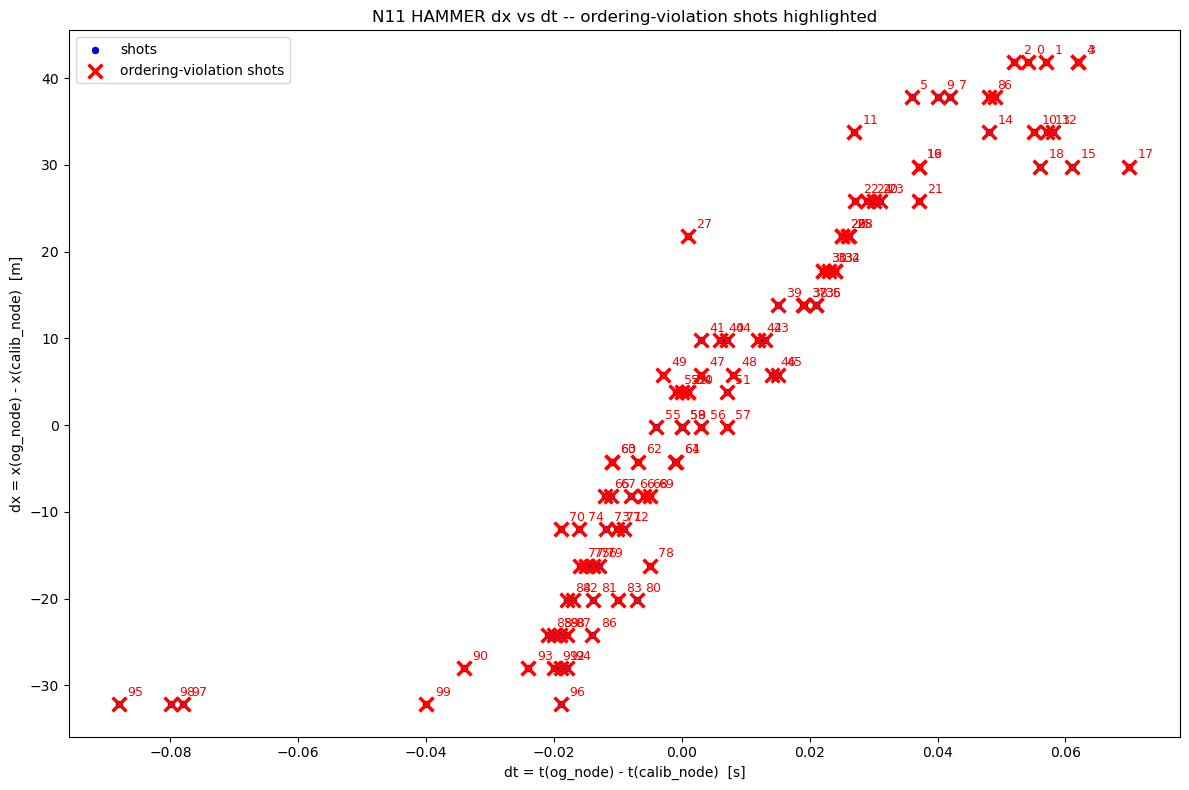

In [6]:
if len(flagged_local) > 0:
    # collect every shot index involved in any flagged pair, along with
    # how many flagged pairs each one appears in
    from collections import Counter
    involved_shots = list(flagged_local["shot_a_index"]) + \
                      list(flagged_local["shot_b_index"])
    shot_flag_counts = Counter(involved_shots)

    highlighted_indices = list(shot_flag_counts.keys())
    highlighted_rows = qc_table[
        qc_table["shot_index"].isin(highlighted_indices)
    ]

    print(f"\nShots highlighted on plot (appearing in an ordering-"
          f"violation pair), with how many flagged pairs each appears in "
          f"(higher = stronger candidate for the actual bad pick):")
    for shot_idx, count in sorted(shot_flag_counts.items(), key=lambda x: -x[1]):
        print(f"  shot {shot_idx}: flagged in {count} pair(s)")
else:
    highlighted_rows = qc_table.iloc[0:0]  # empty, nothing to highlight

plt.figure(figsize=(12, 8))
plt.scatter(dt, dx, color="blue", s=25, edgecolors="k", linewidths=0.3,
            label="shots")

if len(highlighted_rows) > 0:
    plt.scatter(highlighted_rows["dt_sec"], highlighted_rows["dx_m"],
                color="red", s=100, marker="x", linewidths=2.5,
                label="ordering-violation shots")
    # annotate each highlighted point with its shot index so it's easy
    # to match back to the printed output / CSV
    for _, r in highlighted_rows.iterrows():
        plt.annotate(str(int(r["shot_index"])),
                     (r["dt_sec"], r["dx_m"]),
                     textcoords="offset points", xytext=(6, 6),
                     fontsize=9, color="red")

plt.xlabel("dt = t(og_node) - t(calib_node)  [s]")
plt.ylabel("dx = x(og_node) - x(calib_node)  [m]")
plt.title("N11 HAMMER dx vs dt -- ordering-violation shots highlighted")
plt.legend()
plt.tight_layout()
#plt.savefig(r"D:\arrival_markers\arrival_plots\N11_hammer_dx_vs_dt_ordering_flagged.png", dpi=150)
plt.show()

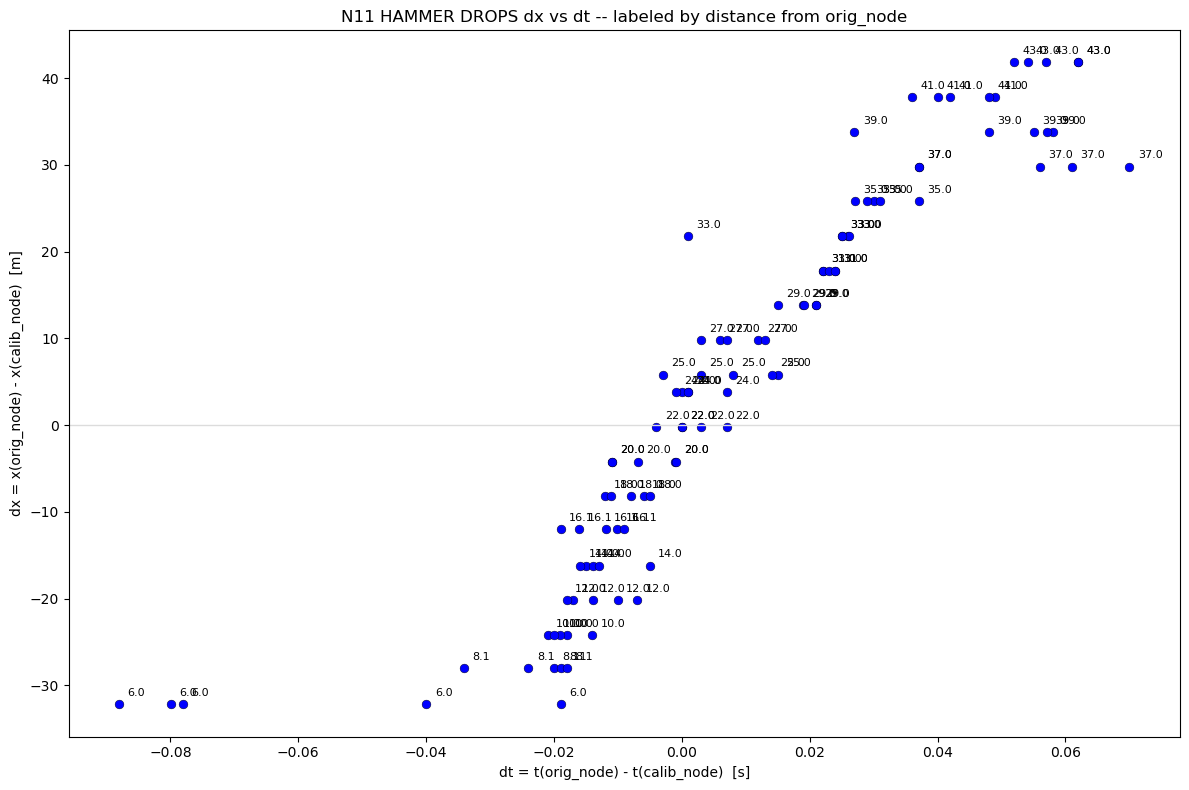

In [7]:
plt.figure(figsize=(12, 8))
sc = plt.scatter(dt, dx, color="blue", s=40, edgecolors="k", linewidths=0.3, label="distance from og_node")
plt.axhline(y=0, color='gainsboro', linewidth=1)

# cbar = plt.colorbar(sc)
# cbar.set_label("distance from og_node  [m]")

# label each point directly with its actual distance-from-og_node value
for _, r in qc_table.iterrows():
    plt.annotate(f"{r['dist_og_node']:.1f}",
                 (r["dt_sec"], r["dx_m"]),
                 textcoords="offset points", xytext=(6, 6),
                 fontsize=8, color="black")
plt.xlabel("dt = t(orig_node) - t(calib_node)  [s]")
plt.ylabel("dx = x(orig_node) - x(calib_node)  [m]")
plt.title("N11 HAMMER DROPS dx vs dt -- labeled by distance from orig_node")
plt.tight_layout()
#plt.savefig(r"D:\arrival_markers\arrival_plots\N11_hammer_dx_vs_dt_colorgradient.png",dpi=150)
plt.show()

C:\Users\zzawol\AppData\Local\Temp\1\ipykernel_27600\86614786.py:21: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap("coolwarm", max_repeats)


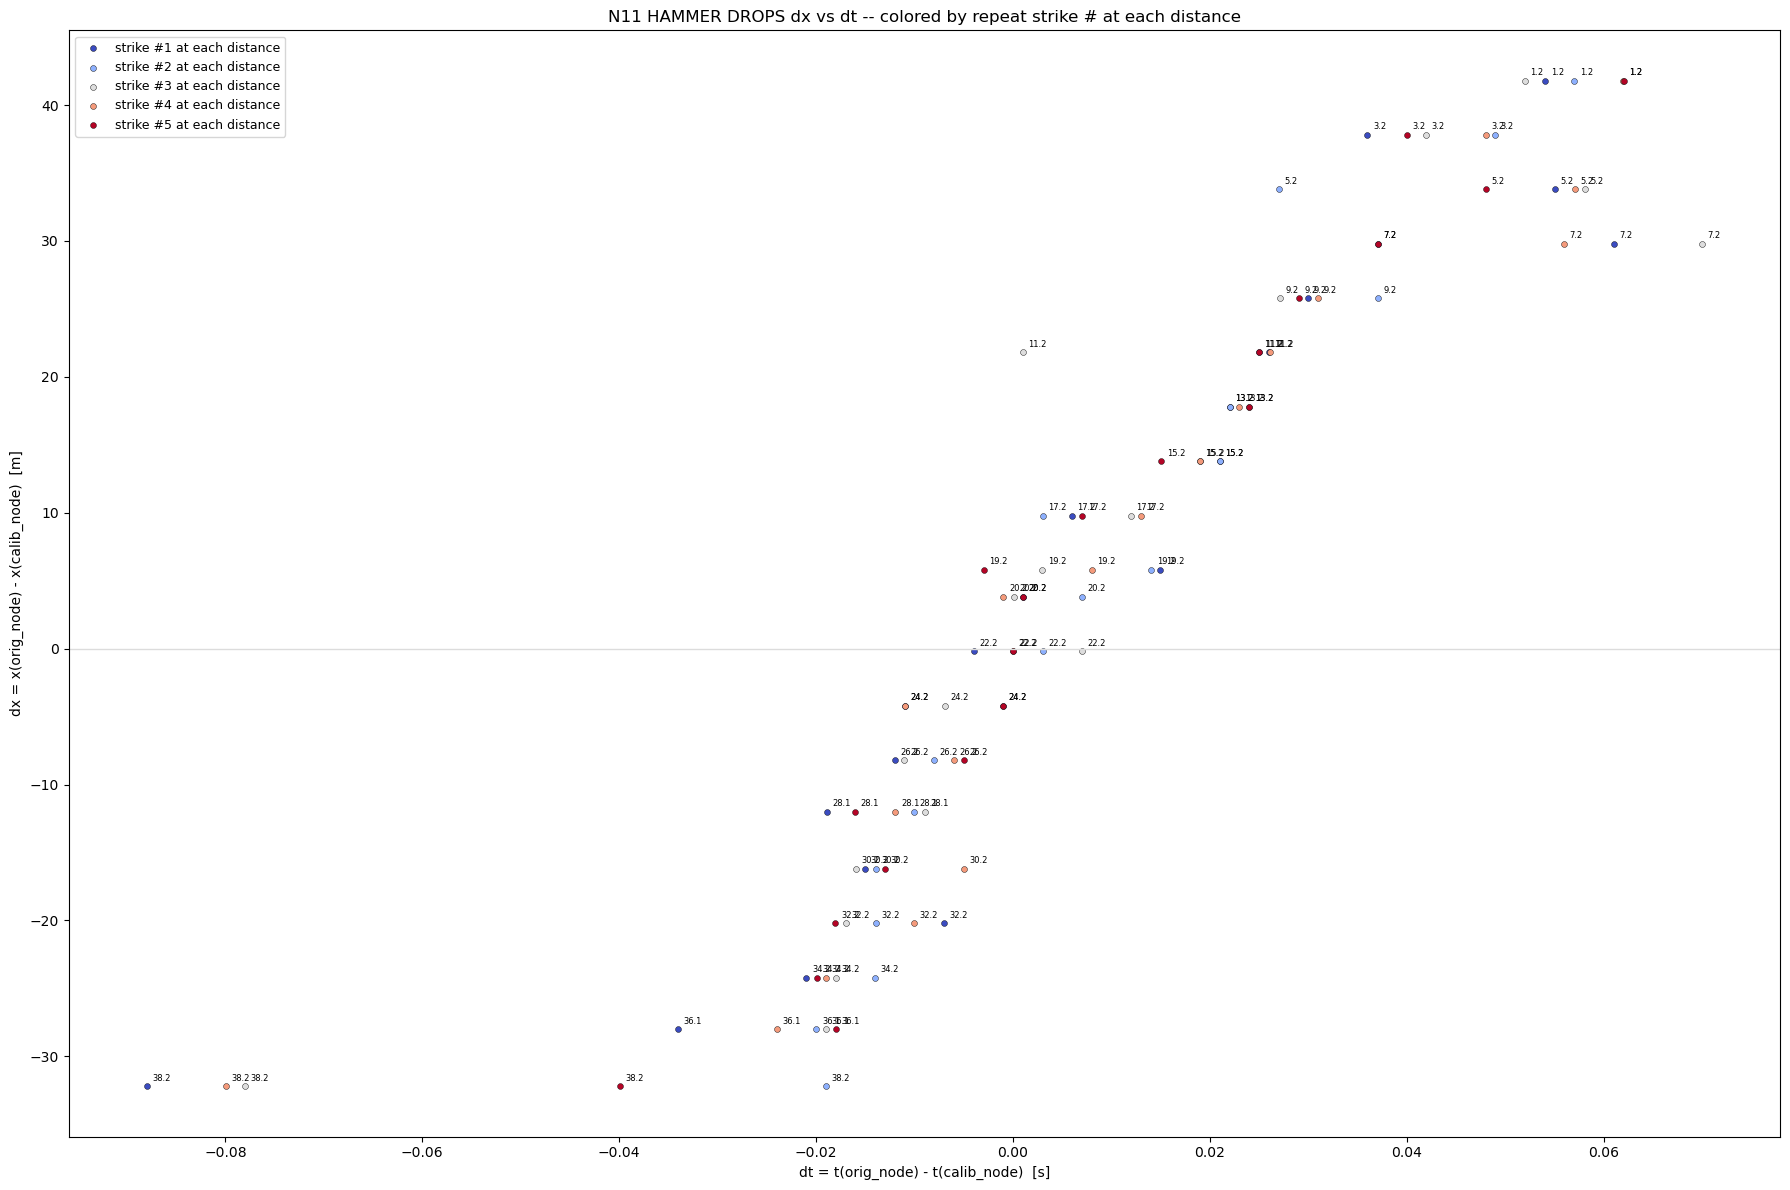

In [11]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors

## for hammer strikes, make sure the points are labeled wrto calib --> orig node
## should be 43, 41, etc
## check the rock display for this too

# --- figure out each shot's "repeat index" within its distance group ---
# groupby preserves original row order within each group by default, so
# cumcount() gives 0,1,2,3,4 for the 1st,2nd,3rd,4th,5th shot at that
# distance, in the order they appear in the file
qc_table["repeat_index"] = qc_table.groupby("dist_calib_node").cumcount()

# how many repeats does the largest group have? (usually 5, but this
# adapts automatically if some locations have fewer/more)
max_repeats = qc_table["repeat_index"].max() + 1

# build a distinct color for each repeat index (1st, 2nd, 3rd...) using
# a qualitative colormap -- distinguishable color gradient
#cmap = cm.get_cmap("viridis", max_repeats)
cmap = cm.get_cmap("coolwarm", max_repeats)

# --- plot ---
plt.figure(figsize=(18, 12))

for rep_idx in range(max_repeats):
    subset = qc_table[qc_table["repeat_index"] == rep_idx]
    plt.scatter(subset["dt_sec"], subset["dx_m"],
                color=cmap(rep_idx), s=18, edgecolors="k", linewidths=0.3,
                label=f"strike #{rep_idx + 1} at each distance")
for rep_idx in range(max_repeats):
    subset = qc_table[qc_table["repeat_index"] == rep_idx]
    plt.scatter(subset["dt_sec"], subset["dx_m"],
                color=cmap(rep_idx / max(max_repeats - 1, 1)),
                s=18, edgecolors="k", linewidths=0.3,
                label=f"strike #{rep_idx + 1} at each distance")


plt.axhline(y=0, color="gainsboro", linewidth=1)

# label each point with its distance value, smaller font + tighter offset
# to reduce clutter given the bigger figure/smaller points
for _, r in qc_table.iterrows():
    plt.annotate(f"{r['dist_calib_node']:.1f}",
                 (r["dt_sec"], r["dx_m"]),
                 textcoords="offset points", xytext=(4, 4),
                 fontsize=6, color="black")

plt.xlabel("dt = t(orig_node) - t(calib_node)  [s]")
plt.ylabel("dx = x(orig_node) - x(calib_node)  [m]")
plt.title("N11 HAMMER DROPS dx vs dt -- colored by repeat strike # at each distance")
plt.legend(loc="best", fontsize=9)
plt.tight_layout()
#plt.savefig(r"D:\arrival_markers\arrival_plots\N11_hammer_dx_vs_dt_repeatcolor.png", dpi=200)
plt.show()

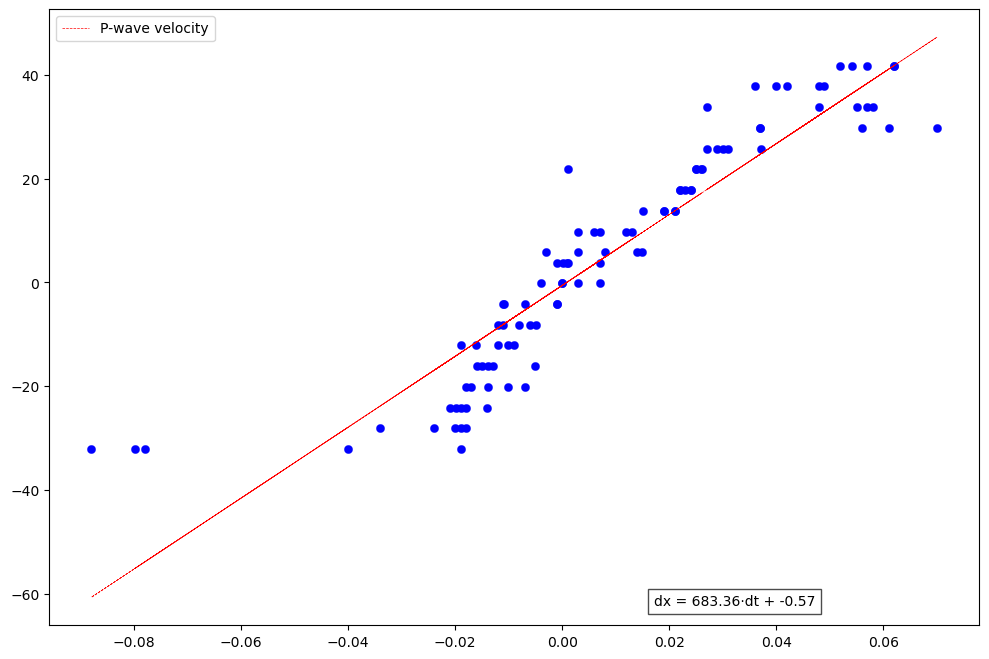

y = mx + b => dx = slope*dt + intercept => dx = 683.3570494336931*dt + -0.5683180604410041
slope = avg velocity: 683.3570494336931
intercept: -0.5683180604410041
    dist_og_node      dx_m          dt_sec                  v_p
0           43.0      41.8        0.054066           773.126550
1           43.0      41.8        0.057027           732.984818
2           43.0      41.8        0.052008           803.727527
3           43.0      41.8        0.062010           674.081694
4           43.0      41.8        0.062026           673.915852
..           ...  ..   ...   ...       ...     ...          ...
95           6.0     -32.2       -0.087999           365.914792
96           6.0     -32.2       -0.018983          1696.264641
97           6.0     -32.2       -0.078023           412.700306
98           6.0     -32.2       -0.079913           402.938694
99           6.0     -32.2       -0.039956           805.894220

[100 rows x 7 columns]


another vel_p: 0      773.126550
1      732.

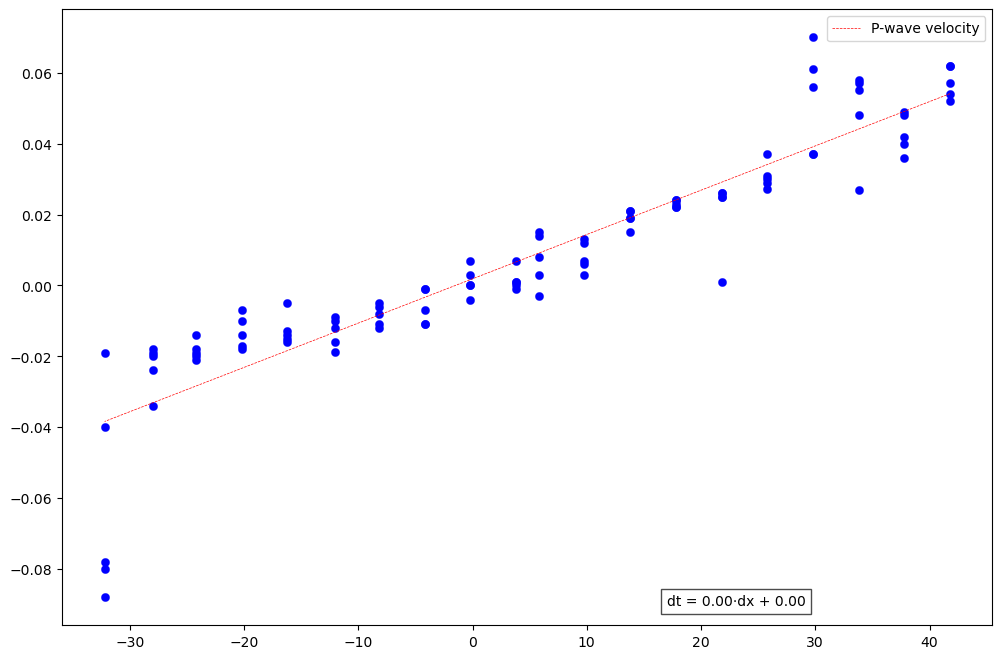

y = mx + b => dt = slope*dx + intercept => dt = 0.0012500233021896594*dx + 0.0018599575234458463
slope = avg velocity: 0.0012500233021896594
intercept: 0.0018599575234458463
    dist_og_node      dx_m          dt_sec                  v_p
0           43.0      41.8        0.054066           773.126550
1           43.0      41.8        0.057027           732.984818
2           43.0      41.8        0.052008           803.727527
3           43.0      41.8        0.062010           674.081694
4           43.0      41.8        0.062026           673.915852
..           ...  ..   ...   ...       ...     ...          ...
95           6.0     -32.2       -0.087999           365.914792
96           6.0     -32.2       -0.018983          1696.264641
97           6.0     -32.2       -0.078023           412.700306
98           6.0     -32.2       -0.079913           402.938694
99           6.0     -32.2       -0.039956           805.894220

[100 rows x 7 columns]


another vel_p: 0      773.126550

In [17]:
# compute slope of best fit line
plt.figure(figsize=(12,8))
slope, intercept = np.polyfit(dt, dx, 1)
plt.scatter(dt, dx, color="blue", linewidth=0.2)
plt.plot(dt, slope*dt + intercept, color='red', linestyle='--', linewidth=0.5, label='P-wave velocity')
#plt.text(0.65, 0.05, f'dx = {slope:.2f}dt + {intercept:.2f}', size=10)
plt.text(0.65, 0.05, f"dx = {slope:.2f}·dt + {intercept:.2f}",
          transform=plt.gca().transAxes, va="top", fontsize=10,
          bbox=dict(facecolor="white", alpha=0.7))
plt.legend()
plt.show()
print(f"y = mx + b => dx = slope*dt + intercept => dx = {slope}*dt + {intercept}")
print(f"slope = avg velocity: {slope}")
print(f"intercept: {intercept}")
p_velocity = dx/dt
#print(f"p-wave velocities:\n {p_velocity}")

import pandas as pd
dx_dt_table = pd.DataFrame({
    "dist_og_node": og_node_x["x1"],
    "   ": " ",
    "dx_m": dx,
    "     ": " ",
    "dt_sec": dt,
    "       ": " ",
    "v_p": p_velocity,
})
print(dx_dt_table)
print("\n")
vel_p = (transect_x - 2*og_node_x["x1"]) / -dt
print(f"another vel_p: {vel_p}")




# compute slope of best fit line
plt.figure(figsize=(12,8))
slope, intercept = np.polyfit(dx, dt, 1)
plt.scatter(dx, dt, color="blue", linewidth=0.2)
plt.plot(dx, slope*dx + intercept, color='red', linestyle='--', linewidth=0.5, label='P-wave velocity')
#plt.text(0.65, 0.05, f'dx = {slope:.2f}dt + {intercept:.2f}', size=10)
plt.text(0.65, 0.05, f"dt = {slope:.2f}·dx + {intercept:.2f}",
          transform=plt.gca().transAxes, va="top", fontsize=10,
          bbox=dict(facecolor="white", alpha=0.7))
plt.legend()
plt.show()
print(f"y = mx + b => dt = slope*dx + intercept => dt = {slope}*dx + {intercept}")
print(f"slope = avg velocity: {slope}")
print(f"intercept: {intercept}")
p_velocity = dx/dt
#print(f"p-wave velocities:\n {p_velocity}")

import pandas as pd
dx_dt_table = pd.DataFrame({
    "dist_og_node": og_node_x["x1"],
    "   ": " ",
    "dx_m": dx,
    "     ": " ",
    "dt_sec": dt,
    "       ": " ",
    "v_p": p_velocity,
})
print(dx_dt_table)
print("\n")
vel_p = (transect_x - 2*og_node_x["x1"]) / -dt
print(f"another vel_p: {vel_p}")

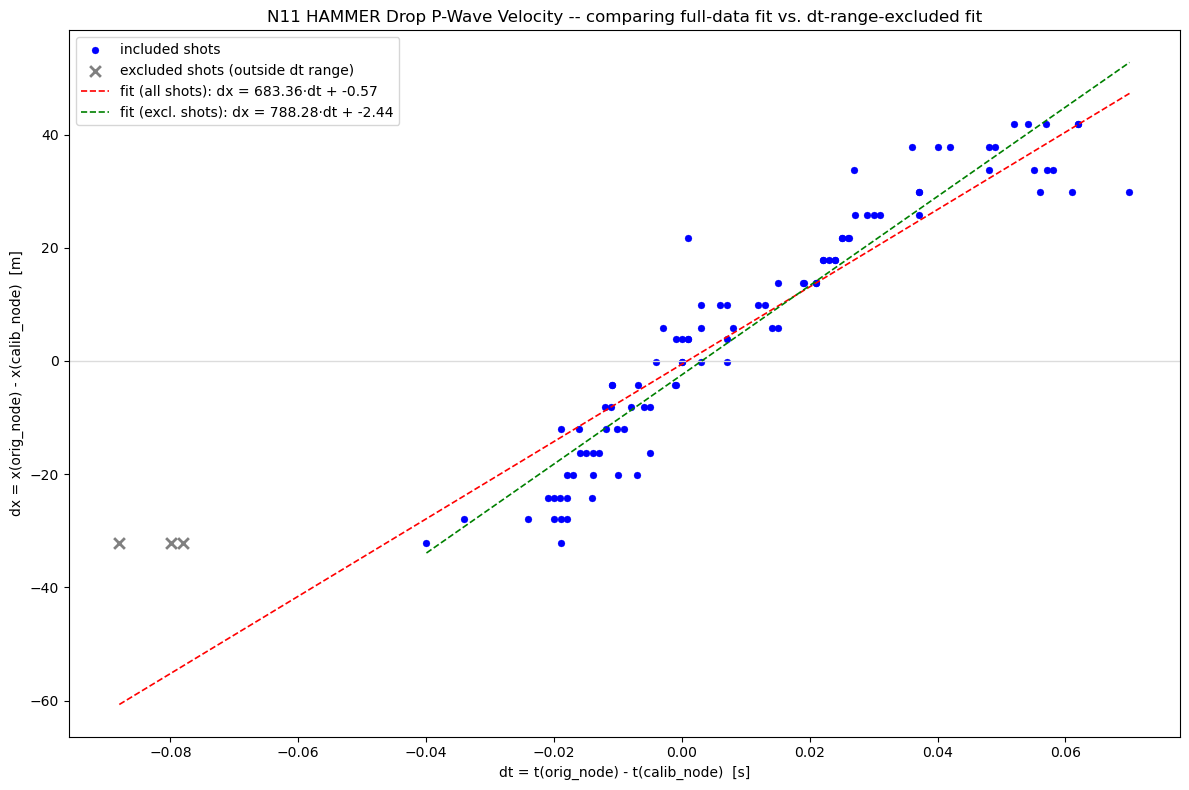

FULL-DATA FIT: per-shot table
 dist_og_node      dx_m          dt_sec                  v_p
         43.0      41.8        0.054066           773.126550
         43.0      41.8        0.057027           732.984818
         43.0      41.8        0.052008           803.727527
         43.0      41.8        0.062010           674.081694
         43.0      41.8        0.062026           673.915852
         41.0      37.8        0.036008          1049.763249
         41.0      37.8        0.048964           771.999142
         41.0      37.8        0.041965           900.740215
         41.0      37.8        0.048000           787.502313
         41.0      37.8        0.040028           944.336721
         39.0      33.8        0.055022           614.302381
         39.0      33.8        0.026984          1252.573102
         39.0      33.8        0.058073           582.028025
         39.0      33.8        0.057049           592.475235
         39.0      33.8        0.048035           703.6

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# fit 1: all points, no exclusion
slope_all, intercept_all = np.polyfit(dt, dx, 1)

# fit 2: excluding points outside a chosen dt range
dt_lower, dt_upper = -0.06, 0.08 # set exclusion bounds

mask = (dt > dt_lower) & (dt < dt_upper)
dt_fit = dt[mask]
dx_fit = dx[mask]

slope_excl, intercept_excl = np.polyfit(dt_fit, dx_fit, 1)

# --- plot ---
plt.figure(figsize=(12, 8))

# all points, in blue -- points excluded from fit 2 are marked separately
plt.scatter(dt[mask], dx[mask], color="blue", s=25, linewidth=0.2,
            label="included shots")
plt.scatter(dt[~mask], dx[~mask], color="gray", s=60, marker="x",
            linewidths=2, label="excluded shots (outside dt range)")
plt.axhline(y=0, color='gainsboro', linewidth=1)

# fit line 1: all points (drawn across the full dt range)
dt_line_all = np.linspace(dt.min(), dt.max(), 100)
plt.plot(dt_line_all, slope_all * dt_line_all + intercept_all,
          color="red", linestyle="--", linewidth=1.2,
          label=f"fit (all shots): dx = {slope_all:.2f}·dt + {intercept_all:.2f}")

# fit line 2: excluding chosen dt-range points
# drawn only across the included points' range, so it doesn't
# visually extrapolate beyond where it was actually fit
dt_line_excl = np.linspace(dt_fit.min(), dt_fit.max(), 100)
plt.plot(dt_line_excl, slope_excl * dt_line_excl + intercept_excl,
          color="green", linestyle="--", linewidth=1.2,
          label=f"fit (excl. shots): dx = {slope_excl:.2f}·dt + {intercept_excl:.2f}")

plt.xlabel("dt = t(orig_node) - t(calib_node)  [s]")
plt.ylabel("dx = x(orig_node) - x(calib_node)  [m]")
plt.title("N11 HAMMER Drop P-Wave Velocity -- comparing full-data fit vs. dt-range-excluded fit")
plt.legend(loc="best")
plt.tight_layout()
plt.show()

# per-shot v_p
p_velocity = dx / dt

# table 1: all shots
dx_dt_table_all = pd.DataFrame({
    "dist_og_node": og_node_x["x1"],
    "   ": " ",
    "dx_m": dx,
    "     ": " ",
    "dt_sec": dt,
    "       ": " ",
    "v_p": p_velocity,
})
print("FULL-DATA FIT: per-shot table")
print(dx_dt_table_all.to_string(index=False))
print(f"\nFit slope (v_p, all shots): {slope_all:.3f} m/s\n")
print("\n")

# table 2: only shots included in the dt-range-excluded fit
dx_dt_table_excl = pd.DataFrame({
    "dist_og_node": og_node_x["x1"][mask],
    "   ": " ",
    "dx_m": dx[mask],
    "     ": " ",
    "dt_sec": dt[mask],
    "       ": " ",
    "v_p": p_velocity[mask],
})
print("EXCLUDED-ENDS FIT: per-shot table")
print(dx_dt_table_excl.to_string(index=False))
print(f"\nFit slope (v_p, excl. ends): {slope_excl:.3f} m/s")

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm


def load_and_prepare(og_t_path, calib_t_path, x_path, transect_x, skiprows=1):
    """
    Load one leg's arrival picks and distances, and compute dt/dx.

    Works identically for either leg -- just point it at that leg's own
    files. Returns a qc_table with everything needed for plotting.
    """
    # og_node_t = pd.read_csv(t1_path, skiprows=skiprows, header=None, names=["t1"])
    # calib_node_t = pd.read_csv(t2_path, skiprows=skiprows, header=None, names=["t2"])

    og_node_t = pd.read_csv(og_t_path, skiprows=1, header=None, names=["t1"])
    calib_node_t = pd.read_csv(calib_t_path, skiprows=1, header=None, names=["t2"])
        
    og_node_t["t1"] = pd.to_datetime(og_node_t["t1"])
    calib_node_t["t2"] = pd.to_datetime(calib_node_t["t2"])

    og_node_x = pd.read_csv(x_path=hammer_x_path, header=None, names=["x1"])  # change to desired distance file (hammer vs rock distances)
    calib_node_x = pd.DataFrame({"x2": transect_x - og_node_x["x1"]})

    assert len(og_node_t) == len(calib_node_t) == len(og_node_x), (
        f"Length mismatch: t1={len(og_node_t)}, t2={len(calib_node_t)}, "
        f"x={len(og_node_x)} -- fix before proceeding."
    )

    dt = (og_node_t["t1"] - calib_node_t["t2"]).dt.total_seconds()
    dx = og_node_x["x1"] - calib_node_x["x2"]

    qc_table = pd.DataFrame({
        "shot_index": np.arange(len(dt)),
        "t1_og_node": og_node_t["t1"],
        "t2_calib_node": calib_node_t["t2"],
        "dist_og_node": og_node_x["x1"],
        "dist_calib_node": calib_node_x["x2"],
        "dt_sec": dt,
        "dx_m": dx,
    })
    return qc_table


def plot_leg(qc_table, distance_col, title, save_path):
    """
    Plot dx vs dt for one leg, colored by repeat-strike index at each
    distance, and labeled with the given distance column's values.

    distance_col: which column to use for grouping/labeling --
    "dist_og_node" for the outbound leg (og->calib, increasing),
    "dist_calib_node" for the return leg (calib->og, decreasing).
    """
    qc_table = qc_table.copy()
    qc_table["repeat_index"] = qc_table.groupby(distance_col).cumcount()
    max_repeats = qc_table["repeat_index"].max() + 1
    cmap = cm.get_cmap("viridis", max_repeats)

    plt.figure(figsize=(18, 12))

    for rep_idx in range(max_repeats):
        subset = qc_table[qc_table["repeat_index"] == rep_idx]
        plt.scatter(subset["dt_sec"], subset["dx_m"],
                    color=cmap(rep_idx / max(max_repeats - 1, 1)),
                    s=18, edgecolors="k", linewidths=0.3,
                    label=f"strike #{rep_idx + 1} at each distance")

    plt.axhline(y=0, color="gainsboro", linewidth=1)

    for _, r in qc_table.iterrows():
        plt.annotate(f"{r[distance_col]:.1f}",
                     (r["dt_sec"], r["dx_m"]),
                     textcoords="offset points", xytext=(4, 4),
                     fontsize=6, color="dimgray")

    plt.xlabel("dt = t(orig_node) - t(calib_node)  [s]")
    plt.ylabel("dx = x(orig_node) - x(calib_node)  [m]")
    plt.title(title)
    plt.legend(loc="best", fontsize=9)
    plt.tight_layout()
    plt.savefig(save_path, dpi=200)
    plt.show()

    return qc_table  # returned so you can inspect/export shot_index,
                      # timestamps, and distances for Snuffler lookup


# ==============================================================================
# LEG 1: OUTBOUND (og_node -> calib_node), distances increasing
# ==============================================================================

qc_outbound = load_and_prepare(
    t1_path=r"D:\arrival_markers\2511\2511_outbound_markers.txt",
    t2_path=r"D:\arrival_markers\C2511\C2511_outbound_markers.txt",
    x1_path=r"D:\arrival_markers\arrival_dx\2511_outbound_x.txt",
    transect_x=44.2,
)

qc_outbound = plot_leg(
    qc_outbound,
    distance_col="dist_og_node",
    title="N11 OUTBOUND (og\u2192calib) dx vs dt -- labeled by distance from og_node",
    save_path=r"D:\arrival_markers\arrival_plots\N11_outbound_dx_vs_dt.png",
)

qc_outbound.to_csv(r"D:\arrival_markers\arrival_plots\N11_outbound_qc_table.csv", index=False)


# ==============================================================================
# LEG 2: RETURN (calib_node -> og_node), distances decreasing
# ==============================================================================

qc_return = load_and_prepare(
    og_t_path=r"D:\arrival_markers\2511\2511_return_markers.txt",
    calib_t_path=r"D:\arrival_markers\C2511\C2511_return_markers.txt",
    x_path=r"D:\arrival_markers\arrival_dx\2511_return_x.txt",
    transect_x=44.2,
)

qc_return = plot_leg(
    qc_return,
    distance_col="dist_calib_node",
    title="N11 RETURN (calib\u2192og) dx vs dt -- labeled by distance from calib_node",
    save_path=r"D:\arrival_markers\arrival_plots\N11_return_dx_vs_dt.png",
)

qc_return.to_csv(r"D:\arrival_markers\arrival_plots\N11_return_qc_table.csv", index=False)



og_t_path = r"D:\arrival_markers\2511\2511_hammer_markers_clean.txt"
calib_t_path = r"D:\arrival_markers\C2511\C2511_hammer_markers_clean_later_arrivals.txt"
hammer_x_path = r"D:\arrival_markers\arrival_dx\N11_hammer_dx.txt"
rock_x_path = r"D:\arrival_markers\arrival_dx\N11_rock_dx.txt"